# Evaluación final sobre junio y análisis de errores por segmento

Semana 12 del plan de trabajo (proposal.md, sección 13).

Hasta el notebook 04b_tamano_muestra.ipynb, junio (test) no se había tocado para ninguna decisión: todo lo de las semanas 9-11 (baselines, árboles, búsqueda de hiperparámetros, tamaño de muestra) se evaluó sobre mayo (validación).
 
Este notebook hace lo que falta:

1. Entrena el modelo final una sola vez, con la configuración de outputs/config_modelo_final.json (LightGBM, hiperparámetros de la semana 11, 1710 árboles, entrenado con el 50% de los datos (decisión tomada en 04b)).
2. Para esta evaluación, el entrenamiento usa enero a mayo completos (ya no se reserva mayo como validación).
3. Predice sobre junio y reporta MAE/RMSLE una sola vez. No se ajusta nada después de ver este número.
4. Analiza los errores por segmento (zona, hora, distancia), conectando con los sesgos ya anticipados en proposal.md sección 12.



In [2]:
import sys
sys.path.append('..')

import json
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_log_error

import src.features as features
features.RUTA_ZONAS = Path('../data/Taxi_Zone_Lookup.csv') 

from src.data import cargar_todo, MESES
from src.features import construir_preprocesador, preparar_xy

SEED = 42
np.random.seed(SEED)

## 1. Configuración final (notebook 04b)

Se carga tal cual quedó guardada.

In [3]:
with open('../outputs/config_modelo_final.json') as f:
    config = json.load(f)
config

{'modelo': 'LightGBM',
 'params': {'objective': 'regression_l1',
  'learning_rate': 0.05,
  'num_leaves': 281,
  'min_child_samples': 30,
  'subsample': 0.78,
  'colsample_bytree': 0.685,
  'reg_alpha': 5.094,
  'reg_lambda': 0.3762},
 'n_estimators': 1710,
 'params_fijos': {'subsample_freq': 1,
  'n_jobs': -1,
  'random_state': 42,
  'verbose': -1},
 'target': 'log1p(trip_duration_min)',
 'features_excluidas': [],
 'sample_frac': 0.5,
 'seed': 42,
 'cv_MAE': 3.3587457653507613,
 'cv_RMSLE': 0.3029249475647775,
 'val_mayo': {'MAE': 3.918024653311591, 'RMSLE': 0.312452141786462},
 'origen': 'params de outputs/mejores_hiperparametros.json (notebook 04); n_estimators recalculado con 50 % en notebook 04b',
 'validacion': 'TimeSeriesSplit(n_splits=3) sobre enero-abril, SAMPLE_FRAC=0.5, SEED=42'}

## 2. Carga de los 6 meses

SAMPLE_FRAC = 0.5, como se decidió en 04b.



In [4]:
SAMPLE_FRAC = config.get('sample_frac', 0.5)

df = cargar_todo(meses=MESES, sample_frac=SAMPLE_FRAC, seed=SEED)
print(f"Filas tras limpieza y muestreo ({SAMPLE_FRAC:.0%} por mes): {len(df):,}")
df['mes'].value_counts().sort_index()

Filas tras limpieza y muestreo (50% por mes): 11,327,687


mes
2025-01    1648803
2025-02    1697281
2025-03    1962254
2025-04    1872766
2025-05    2138529
2025-06    2008054
Name: count, dtype: int64

## 3. Split final: entrenamiento (enero-mayo) vs. test (junio)

A diferencia de los notebooks 02-04b, aquí mayo deja de ser validación y pasa a formar parte del entrenamiento. Ya cumplió su rol de comparar modelos y buscar hiperparámetros. Junio se toca por primera y única vez.

In [5]:
mes_num = df['tpep_pickup_datetime'].dt.month

train_final = df[mes_num.between(1, 5)].copy()
test = df[mes_num == 6].copy()

print(f"Train final (ene-may): {len(train_final):,}")
print(f"Test (junio):          {len(test):,}")

Train final (ene-may): 9,319,633
Test (junio):          2,008,054


## 4. Features y entrenamiento del modelo final
No escalamos las variables: a LightGBM no le afecta la escala, a diferencia de la regresión lineal.

El preprocesador se ajusta solo con train (enero-mayo), nunca con junio, para no filtrar información del futuro.

Entrenamos sobre log1p(duración) porque hay pocos viajes muy largos que distorsionarían el entrenamiento; al final volvemos a minutos con expm1.

In [7]:
X_tr, y_tr = preparar_xy(train_final, target_col='trip_duration_min', usar_log_target=True)
X_te, y_te_log = preparar_xy(test, target_col='trip_duration_min', usar_log_target=True)
y_te = test['trip_duration_min'].to_numpy(dtype=float)

preprocesador = construir_preprocesador(escalar_numericas=False)
X_tr_proc = preprocesador.fit_transform(X_tr, y_tr)
X_te_proc = preprocesador.transform(X_te)

modelo_final = lgb.LGBMRegressor(
    **config['params'],
    **config['params_fijos'],
    n_estimators=config['n_estimators'],
)
modelo_final.fit(X_tr_proc, y_tr)
print("Modelo entrenado.")

C:\Users\Joaquin\Documents\Joaquin\U\machine\proyecto\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Modelo entrenado.


## 5. Evaluación final sobre junio (una sola vez)

In [8]:
pred_log = modelo_final.predict(X_te_proc)
pred_min = np.clip(np.expm1(pred_log), 0, None)

mae_test = mean_absolute_error(y_te, pred_min)
rmsle_test = np.sqrt(mean_squared_log_error(y_te, pred_min))

print(f"MAE  (junio, test) = {mae_test:.3f} min")
print(f"RMSLE(junio, test) = {rmsle_test:.4f}")

test = test.copy()
test['pred_min'] = pred_min
test['error_abs'] = (test['trip_duration_min'] - test['pred_min']).abs()

MAE  (junio, test) = 3.694 min
RMSLE(junio, test) = 0.3066


## 6. Análisis de errores por segmento

No basta con el MAE global: hay que ver dónde falla más el modelo, conectando
con los sesgos anticipados en proposal.md sección 12.

In [9]:
# Por hora del día
test['hora'] = test['tpep_pickup_datetime'].dt.hour
error_por_hora = test.groupby('hora')['error_abs'].mean()
print("MAE por hora del día:")
print(error_por_hora.round(2))

MAE por hora del día:
hora
0     2.94
1     2.63
2     2.44
3     2.39
4     2.66
5     2.97
6     3.12
7     3.50
8     3.71
9     3.88
10    4.05
11    4.28
12    4.34
13    4.37
14    4.39
15    4.37
16    4.42
17    4.25
18    3.83
19    3.34
20    3.00
21    2.91
22    3.04
23    3.14
Name: error_abs, dtype: float64


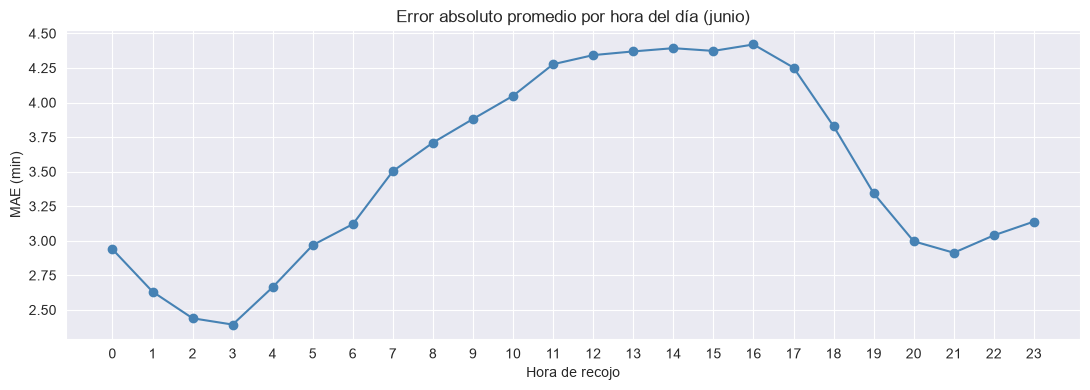

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))
plt.plot(error_por_hora.index, error_por_hora.values, marker='o', color='steelblue')
plt.xlabel('Hora de recojo')
plt.ylabel('MAE (min)')
plt.title('Error absoluto promedio por hora del día (junio)')
plt.xticks(range(24))
plt.tight_layout()
plt.savefig('../reports/figures/09_error_por_hora.png', dpi=150)
plt.show()

In [11]:
# Por zona de recojo (top 15 por volumen)
top_zonas = test['PULocationID'].value_counts().head(15).index
error_por_zona = (
    test[test['PULocationID'].isin(top_zonas)]
    .groupby('PULocationID')['error_abs']
    .agg(['mean', 'count'])
    .sort_values('mean')
)
error_por_zona.columns = ['MAE', 'n_viajes']
error_por_zona

,MAE,n_viajes
PULocationID,,
79,2.762566,52928
142,2.900037,54312
236,2.983632,73456
237,3.091380,84511
234,3.202809,53027
48,3.342257,49006
170,3.579441,53799
161,3.593814,83854
163,3.597588,49473


In [12]:
# Por tramo de distancia estimada
test['distancia_tramo'] = pd.cut(
    test['trip_distance'],
    bins=[0, 1, 3, 6, 10, 20, np.inf],
    labels=['0-1mi', '1-3mi', '3-6mi', '6-10mi', '10-20mi', '20mi+'],
)
error_por_distancia = test.groupby('distancia_tramo', observed=True)['error_abs'].agg(['mean', 'count'])
error_por_distancia.columns = ['MAE', 'n_viajes']
error_por_distancia

,MAE,n_viajes
distancia_tramo,,
0-1mi,2.606445,405560
1-3mi,3.087760,930376
3-6mi,4.004627,347129
6-10mi,5.171616,168047
10-20mi,7.538874,143421
20mi+,10.902932,13521


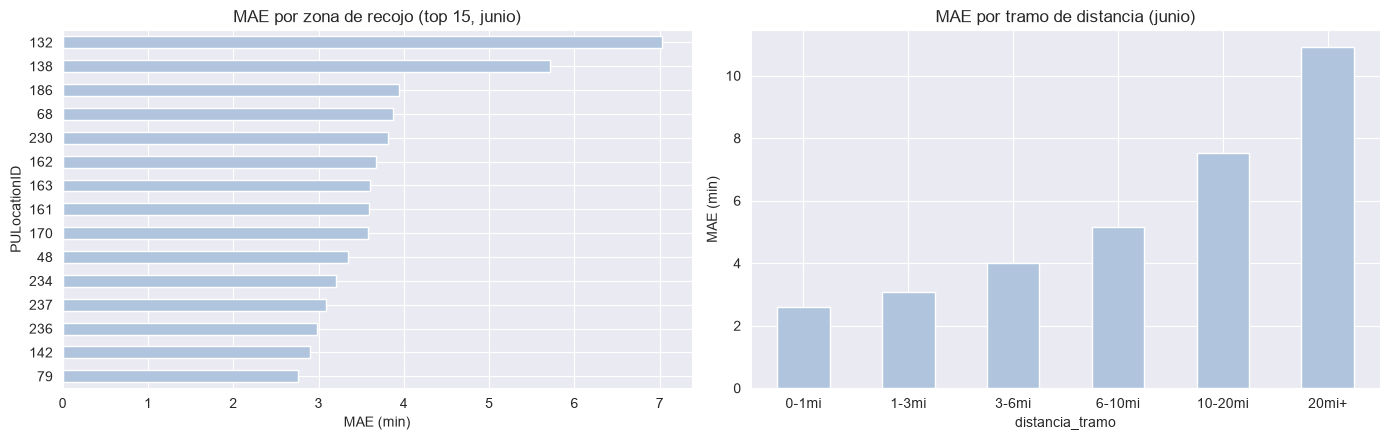

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

error_por_zona['MAE'].plot.barh(ax=axes[0], color='lightsteelblue')
axes[0].set_title('MAE por zona de recojo (top 15, junio)')
axes[0].set_xlabel('MAE (min)')

error_por_distancia['MAE'].plot.bar(ax=axes[1], color='lightsteelblue')
axes[1].set_title('MAE por tramo de distancia (junio)')
axes[1].set_ylabel('MAE (min)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('../reports/figures/10_error_por_segmento.png', dpi=150)
plt.show()

## 7. Comparación con el resto del proyecto

Las métricas de A-K se midieron sobre mayo (validación). Esta fila (L) es la única medida sobre junio (test), y con una configuración de entrenamiento distinta (enero-mayo en vez de enero-abril). 
No son directamente comparables punto a punto, se incluyen para dar contexto, no como una tabla de un solo eje.

In [14]:
resumen_final = {
    'modelo': 'L: LightGBM final (config 04b, train ene-may, test junio)',
    'MAE': float(mae_test),
    'RMSLE': float(rmsle_test),
    'n_train': len(train_final),
    'n_test': len(test),
}
resumen_final

{'modelo': 'L: LightGBM final (config 04b, train ene-may, test junio)',
 'MAE': 3.6939723481428084,
 'RMSLE': 0.3066455093265517,
 'n_train': 9319633,
 'n_test': 2008054}

In [15]:
Path('../outputs').mkdir(exist_ok=True)
with open('../outputs/metrics_evaluacion_final.json', 'w') as f:
    json.dump({
        'resumen': resumen_final,
        'error_por_hora': error_por_hora.round(3).to_dict(),
        'error_por_zona': error_por_zona.reset_index().to_dict(orient='records'),
        'error_por_distancia': error_por_distancia.reset_index().astype(str).to_dict(orient='records'),
    }, f, indent=2, ensure_ascii=False)
print("Guardado en ../outputs/metrics_evaluacion_final.json")

Guardado en ../outputs/metrics_evaluacion_final.json


## 8. Lectura de resultados

**Resultado global:** MAE = 3.694 min, RMSLE = 0.3066 sobre junio (test, evaluado una sola vez). Es mejor que lo obtenido en la validación de mayo (MAE=3.918, RMSLE=0.3125), lo que indica que el modelo generaliza bien y no hay señales de sobreajuste.

**Error por hora del día:** El error es más bajo de madrugada (2-4am, ~2.4-2.6 min) y más alto entre las 11am y las 5pm (~4.3-4.4 min). Tiene sentido: de madrugada hay poco tráfico y los viajes son más predecibles, mientras que en el día el tráfico es más variable (congestión, eventos, clima), lo que hace más difícil predecir la duración exacta.

**Error por zona:** Las zonas con mayor error son 132 y 138, que corresponden a los aeropuertos JFK y LaGuardia, con MAE cercano a 7 min. Esto confirma lo que esperábamos: los viajes desde/hacia aeropuertos tienen mayor variabilidad (tráfico de acceso, tipo de pasajero, distancias largas), algo que el modelo no puede capturar completamente solo con zona/hora/distancia estimada. Las zonas con menor error son 79, 142, 236, 237 estas zonas son de alto volumen en Manhattan, con viajes más cortos y homogéneos.

**Error por distancia:** El error crece de forma consistente con la distancia del viaje, desde
2.6 min (0-1mi) hasta 10.9 min (20mi+). Esto es esperable: viajes más largos tienen más
oportunidades de verse afectados por tráfico, rutas alternativas o paradas, acumulando más
incertidumbre absoluta en la predicción.


## 9. Baselines reentrenados con 50% para comparación justa

Los modelos A-K de los notebooks 02-04b se evaluaron sobre mayo (validación) y en su mayoría,
entrenados con una muestra distinta. Para que la comparación final con L sea justa, aquí se
reentrenan los baselines con la misma muestra (50%, enero-mayo) y se evalúan sobre el mismo
conjunto de test (junio).

In [16]:
resultados_finales = []

def evaluar_final(nombre, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmsle = np.sqrt(mean_squared_log_error(y_true, np.clip(y_pred, 0, None)))
    resultados_finales.append({'modelo': nombre, 'MAE': mae, 'RMSLE': rmsle})
    print(f"{nombre}: MAE={mae:.3f} min, RMSLE={rmsle:.4f}")

In [17]:
# Baseline A: mediana global (entrenada con train_final, enero-mayo)
mediana_global = train_final['trip_duration_min'].median()
pred_A = np.full(len(test), mediana_global)
evaluar_final('A: mediana global', test['trip_duration_min'], pred_A)

A: mediana global: MAE=8.962 min, RMSLE=0.6551


In [18]:
# Baseline B: mediana por zona de recojo + hora (entrenada con train_final)
train_final['hora'] = train_final['tpep_pickup_datetime'].dt.hour
mediana_zona_hora = (
    train_final.groupby(['PULocationID', 'hora'])['trip_duration_min']
    .median()
)

test_zona_hora = test.set_index(['PULocationID', 'hora'])
pred_B = test_zona_hora.index.map(mediana_zona_hora)
pred_B = pd.Series(pred_B, index=test.index).fillna(mediana_global).to_numpy(dtype=float)

evaluar_final('B: mediana por zona y hora', test['trip_duration_min'], pred_B)

B: mediana por zona y hora: MAE=7.475 min, RMSLE=0.5695


**Nota sobre modelos omitidos:** Los modelos C, D, E (Lineal/Ridge/Lasso), F (Random Forest) y G(HistGradientBoosting) se omitieron de esta comparación específica por limitaciones de memoria RAM del equipo. D llegó a intentarse, falló al construir la versión escalada y densa de las features sobre el 50% de los datos (9.3M filas × 41 columnas, ~2.85 GB), algo que F habría agravado aún más al no usar las optimizaciones de LightGBM. El desempeño de estos modelos ya se había caracterizado en las semanas 9-10 sobre muestras menores, sin mejoras relevantes sobre los baselines o el modelo final, por lo que su omisión no compromete las conclusiones de esta comparación.

In [23]:
# Tabla comparativa final (A, B, L)
resultados_finales.append({'modelo': 'L: LightGBM final', 'MAE': mae_test, 'RMSLE': rmsle_test})

tabla_comparativa = pd.DataFrame(resultados_finales).sort_values('MAE').reset_index(drop=True)
tabla_comparativa

,modelo,MAE,RMSLE
0,L: LightGBM final,3.693972,0.306646
1,B: mediana por zona y hora,7.475475,0.569528
2,A: mediana global,8.962432,0.655073


**Lectura de la comparación:** Bajo las mismas condiciones de datos, el modelo final (L) reduce el error a menos de la mitad frente al mejor baseline (B: mediana por zona y hora) y a poco más de un tercio frente al baseline más simple (A: mediana global). Esto confirma que todo el trabajo de las semanas 10-11 (modelos de árboles, búsqueda de hiperparámetros) se tradujo en una mejora real y sustancial sobre predecir y no solo sobre una muestra de validación distinta: la ventaja se mantiene al evaluar sobre el mismo conjunto de test, de forma justa, para los tres modelos.

In [24]:
with open('../outputs/metrics_comparacion_justa.json', 'w') as f:
    json.dump(tabla_comparativa.to_dict(orient='records'), f, indent=2, ensure_ascii=False)
print("Guardado en ../outputs/metrics_comparacion_justa.json")

Guardado en ../outputs/metrics_comparacion_justa.json


**Siguientes pasos (semana 13):** SHAP para interpretar qué variables pesan más en cada predicción,
y discusión formal de sesgos y limitaciones del modelo